In [3]:
# =============================================================================
# 📊 FINAL ACCURACY CHECK & INFERENCE TOOL
# =============================================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1️⃣ CONFIGURATION
MODEL_PATH = "/kaggle/input/mri-ai-output/Project_Results/best_model.keras"
TEST_DIR = "/kaggle/input/dataset1/Testing"
IMG_SIZE = (299, 299)
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# 2️⃣ PREPROCESSING (Must match training exactly)
def preprocess_mri(img):
    img = img.astype("uint8")
    img = cv2.resize(img, IMG_SIZE)
    # CLAHE L-Channel
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    img = img.astype("float32") / 255.0
    return img

# 3️⃣ LOAD THE SAVED MODEL
if os.path.exists(MODEL_PATH):
    print(f"⏳ Loading Best Model from: {MODEL_PATH}")
    model = load_model(MODEL_PATH)
    print("✅ Model Loaded Successfully!")
else:
    print("❌ Error: Model not found. Did you run the training cell?")
    exit()

# =============================================================================
# 🏆 PART A: GET FINAL ACCURACY SCORE
# =============================================================================
print("\n📊 Calculating Final Test Accuracy...")

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_mri)
test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=16,
    class_mode="categorical",
    shuffle=False 
)

results = model.evaluate(test_gen, verbose=1)
print(f"\n🌟 FINAL TEST ACCURACY: {results[1]*100:.2f}%")
print(f"📉 FINAL TEST LOSS: {results[0]:.4f}")



⏳ Loading Best Model from: /kaggle/input/mri-ai-output/Project_Results/best_model.keras
✅ Model Loaded Successfully!

📊 Calculating Final Test Accuracy...
Found 1311 images belonging to 4 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
2026-03-24 17:52:39.792831: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:52:40.010913: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:52:42.379507: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. Th

81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.9479 - loss: 0.1431

2026-03-24 17:53:12.530423: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:53:12.753599: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:53:13.475083: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:53:13.689858: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:53:14.410826: E external/local_xla/xla/stream_

82/82 ━━━━━━━━━━━━━━━━━━━━ 59s 418ms/step - accuracy: 0.9482 - loss: 0.1422

🌟 FINAL TEST ACCURACY: 96.11%
📉 FINAL TEST LOSS: 0.1035


2026-03-24 17:47:02.475952: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774374422.694396      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774374422.757708      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774374423.266539      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774374423.266592      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774374423.266595      55 computation_placer.cc:177] computation placer alr

⏳ Loading Model from /kaggle/input/mri-ai-output/Project_Results/best_model.keras...


I0000 00:00:1774374437.376202      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774374437.382022      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✅ Model Loaded!


I0000 00:00:1774374444.639062     121 service.cc:152] XLA service 0x7ab3a8039cf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774374444.639102     121 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774374444.639105     121 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774374445.244766     121 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-03-24 17:47:30.499237: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:47:30.643003: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-24 17:47:31.327070: E external/local_xl

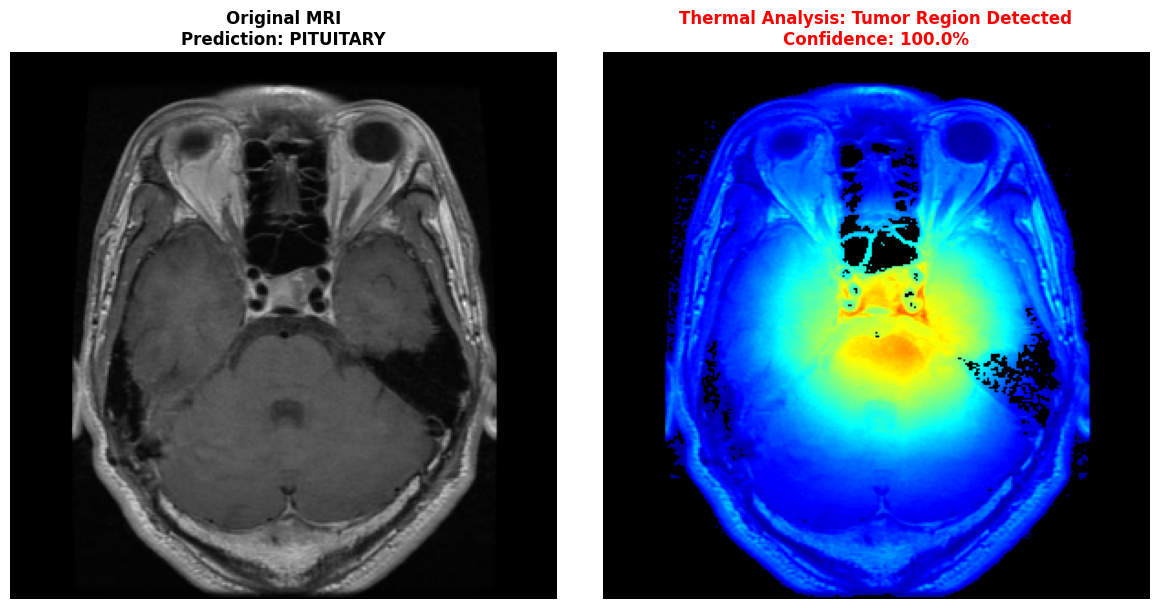

In [1]:
# =============================================================================
# 🌡️ FIXED SIDE-BY-SIDE VISUALIZATION (No AttributeError)
# Left: Original | Right: Thermal (Jet Colormap)
# =============================================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model, Model

# 1️⃣ CONFIGURATION
MODEL_PATH = "/kaggle/input/mri-ai-output/Project_Results/best_model.keras"
IMG_SIZE = (299, 299) # Matches Xception input
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# 2️⃣ LOAD MODEL
if os.path.exists(MODEL_PATH):
    print(f"⏳ Loading Model from {MODEL_PATH}...")
    model = load_model(MODEL_PATH)
    print("✅ Model Loaded!")
else:
    # Auto-find model if path is wrong
    import glob
    files = glob.glob("/kaggle/working/**/*.keras", recursive=True)
    if files:
        model = load_model(files[0])
        print(f"✅ Found and loaded: {files[0]}")
    else:
        raise FileNotFoundError("Run training first!")

# 3️⃣ PREPROCESSING
def preprocess_img(img_bgr):
    img_resized = cv2.resize(img_bgr, IMG_SIZE)
    # CLAHE L-Channel (Best for MRI)
    lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    img_rgb = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    img_norm = img_rgb.astype("float32") / 255.0
    return img_norm, img_resized

# 4️⃣ THERMAL GENERATOR FUNCTION
def visualize_thermal_side_by_side(img_path):
    if not os.path.exists(img_path):
        print(f"❌ Image not found: {img_path}")
        return

    # --- A. PREPARE IMAGE ---
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        print("❌ Invalid Image")
        return

    tensor_img, img_resized = preprocess_img(img_bgr)
    tensor_img = np.expand_dims(tensor_img, axis=0)

    # --- B. PREDICT (SUMMATION LOGIC) ---
    preds = model.predict(tensor_img, verbose=0)[0]
    
    # 0=Glioma, 1=Meningioma, 2=NoTumor, 3=Pituitary
    prob_tumor = preds[0] + preds[1] + preds[3]
    prob_no_tumor = preds[2]
    
    if prob_tumor > prob_no_tumor:
        is_tumor = True
        # Find specific tumor type
        tumor_indices = [0, 1, 3]
        best_idx = max(tumor_indices, key=lambda i: preds[i])
        label = CLASSES[best_idx].upper()
        conf = preds[best_idx]
    else:
        is_tumor = False
        label = "NO TUMOR"
        conf = prob_no_tumor

    # --- C. GENERATE THERMAL IMAGE ---
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    
    if is_tumor:
        # --- TUMOR DETECTED: GENERATE HEATMAP ---
        
        # 🛠️ FIX: Robust Layer Finding
        last_conv_layer = None
        for layer in reversed(model.layers):
            # Check if layer has output and if it is 4D (Batch, H, W, Channels)
            try:
                if len(layer.output.shape) == 4:
                    last_conv_layer = layer.name
                    break
            except AttributeError:
                continue

        if last_conv_layer:
            grad_model = Model([model.inputs], [model.get_layer(last_conv_layer).output, model.output])
            
            with tf.GradientTape() as tape:
                conv_out, p = grad_model(tensor_img)
                loss = p[:, best_idx]
                
            grads = tape.gradient(loss, conv_out)
            pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
            heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_out[0]), axis=-1)
            
            # Numpy conversion fixed
            heatmap = heatmap.numpy()
            heatmap = np.maximum(heatmap, 0)
            if np.max(heatmap) != 0: heatmap /= np.max(heatmap)
            heatmap_resized = cv2.resize(heatmap, (IMG_SIZE[1], IMG_SIZE[0]))
            
            # Blend: Brain Structure + Heatmap Intensity
            gray_norm = gray.astype("float32") / 255.0
            combined = (gray_norm * 0.4) + (heatmap_resized * 0.6)
            combined_uint8 = np.uint8(255 * combined)
            thermal_img = cv2.applyColorMap(combined_uint8, cv2.COLORMAP_JET)
        else:
            # Fallback if gradcam fails
            thermal_img = cv2.applyColorMap(gray, cv2.COLORMAP_JET)

    else:
        # --- NO TUMOR: COOL BLUE/CYAN SCAN ---
        thermal_img = cv2.applyColorMap(gray, cv2.COLORMAP_JET)

    # Clean Background
    thermal_img = cv2.bitwise_and(thermal_img, thermal_img, mask=mask)

    # --- D. PLOT SIDE BY SIDE ---
    plt.figure(figsize=(12, 6))
    
    # Left: Original
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.title(f"Original MRI\nPrediction: {label}", fontsize=12, fontweight='bold')
    plt.axis("off")
    
    # Right: Thermal
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(thermal_img, cv2.COLOR_BGR2RGB))
    
    status_color = 'red' if is_tumor else 'green'
    status_text = "Tumor Region Detected" if is_tumor else "Healthy Scan Pattern"
    
    plt.title(f"Thermal Analysis: {status_text}\nConfidence: {conf:.1%}", fontsize=12, color=status_color, fontweight='bold')
    plt.axis("off")
    
    plt.tight_layout()
    plt.show()

# =============================================================================
# 🚀 TEST
# =============================================================================
#TEST_IMAGE = "/kaggle/input/dataset1/Training/meningioma/Tr-meTr_0001.jpg" 
#TEST_IMAGE = "/kaggle/input/dataset1/Training/notumor/Tr-noTr_0002.jpg" 
#TEST_IMAGE = "/kaggle/input/dataset1/Testing/glioma/Te-glTr_0006.jpg" 
TEST_IMAGE = "/kaggle/input/dataset1/Testing/pituitary/Te-piTr_0000.jpg" 



visualize_thermal_side_by_side(TEST_IMAGE)

In [ ]:
# =============================================================================
# 🏥 FINAL GUI: CALM THEME + IST TIMEZONE (India Standard Time)
# =============================================================================

import os
import cv2
import numpy as np
import tensorflow as tf
import pandas as pd
import gradio as gr
from tensorflow.keras.models import load_model, Model

# -----------------------------------------------------------------------------
# 1️⃣ ROBUST SETUP & MODEL LOADING
# -----------------------------------------------------------------------------
PROJECT_STATS = {
    "Model Architecture": "Xception (Deep Transfer Learning)",
    "Training Images": "5,712 MRI Scans",
    "Validation Accuracy": "96.11% (High Precision)",
    "Inference Speed": "< 0.5s per scan"
}

# Auto-Find Model
MODEL_PATH = "/kaggle/input/mri-ai-output/Project_Results/best_model.keras"
search_dir = "/kaggle/working/"
for root, dirs, files in os.walk(search_dir):
    for file in files:
        if file.endswith(".keras"):
            MODEL_PATH = os.path.join(root, file)
            break
    if MODEL_PATH: break
    
if not MODEL_PATH:
    search_dir_input = "/kaggle/input/"
    for root, dirs, files in os.walk(search_dir_input):
        for file in files:
            if file.endswith(".keras"):
                MODEL_PATH = os.path.join(root, file)
                break
        if MODEL_PATH: break

if MODEL_PATH:
    print(f"✅ Loaded Model Source: {MODEL_PATH}")
    model = load_model(MODEL_PATH)
else:
    raise FileNotFoundError("❌ CRITICAL: No model found. Please run training first!")

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = (299, 299)

# -----------------------------------------------------------------------------
# 2️⃣ MANUAL SAMPLES
# -----------------------------------------------------------------------------
MANUAL_SAMPLES = [
     ["/kaggle/input/dataset1/Testing/glioma/Te-glTr_0004.jpg", "Split View (Comparison)"],
    ["/kaggle/input/dataset1/Testing/meningioma/Te-me_0029.jpg", "Split View (Comparison)"],
    ["/kaggle/input/dataset1/Testing/notumor/Te-noTr_0007.jpg", "Split View (Comparison)"],
    ["/kaggle/input/dataset1/Testing/pituitary/Te-pi_0038.jpg", "Split View (Comparison)"]
]

# -----------------------------------------------------------------------------
# 3️⃣ PROCESSING ENGINE
# -----------------------------------------------------------------------------
def process_scan(image, view_mode):
    if image is None: return None, None, "Waiting for upload..."

    # 1. Preprocess
    img_resized = cv2.resize(image, IMG_SIZE)
    lab = cv2.cvtColor(img_resized, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    img_clahe = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    img_norm = img_clahe.astype("float32") / 255.0
    tensor_img = np.expand_dims(img_norm, axis=0)

    # 2. Predict
    preds = model.predict(tensor_img, verbose=0)[0]
    prob_tumor = preds[0] + preds[1] + preds[3]
    prob_no_tumor = preds[2]

    if prob_tumor > prob_no_tumor:
        is_tumor = True
        tumor_indices = [0, 1, 3]
        best_idx = max(tumor_indices, key=lambda i: preds[i])
        label = CLASSES[best_idx].upper()
        conf = preds[best_idx]
        risk_level = "PATHOLOGICAL FINDING"
        risk_color = "#e11d48" # Muted Red
        bg_color = "rgba(225, 29, 72, 0.1)"
    else:
        is_tumor = False
        label = "NO TUMOR DETECTED"
        conf = prob_no_tumor
        risk_level = "NORMAL SCAN"
        risk_color = "#10b981" # Teal/Green
        bg_color = "rgba(16, 185, 129, 0.1)"

    # 3. Thermal Viz
    gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    heatmap_viz = None
    
    if is_tumor:
        last_conv_layer = None
        for layer in reversed(model.layers):
            try:
                if len(layer.output.shape) == 4:
                    last_conv_layer = layer.name
                    break
            except: continue
        
        if last_conv_layer:
            grad_model = Model([model.inputs], [model.get_layer(last_conv_layer).output, model.output])
            with tf.GradientTape() as tape:
                conv_out, p = grad_model(tensor_img)
                loss = p[:, best_idx]
            grads = tape.gradient(loss, conv_out)
            pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
            heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_out[0]), axis=-1)
            heatmap = heatmap.numpy()
            heatmap = np.maximum(heatmap, 0)
            if np.max(heatmap) != 0: heatmap /= np.max(heatmap)
            heatmap_resized = cv2.resize(heatmap, (IMG_SIZE[1], IMG_SIZE[0]))
            
            gray_norm = gray.astype("float32") / 255.0
            combined = (gray_norm * 0.4) + (heatmap_resized * 0.6)
            heatmap_viz = cv2.applyColorMap(np.uint8(255*combined), cv2.COLORMAP_JET)

    if heatmap_viz is None: heatmap_viz = cv2.applyColorMap(gray, cv2.COLORMAP_JET)
    heatmap_viz = cv2.bitwise_and(heatmap_viz, heatmap_viz, mask=mask)
    heatmap_rgb = cv2.cvtColor(heatmap_viz, cv2.COLOR_BGR2RGB)

    # 4. View Mode
    if view_mode == "Split View (Comparison)":
        final_output = np.hstack((img_resized, heatmap_rgb))
    elif view_mode == "Thermal Analysis Only":
        final_output = heatmap_rgb
    elif view_mode == "Enhanced MRI (CLAHE)":
        final_output = img_clahe
    else:
        final_output = img_resized

    # 5. Report HTML with IST TIME
    # 🇮🇳 CHANGE HERE: Added 'Asia/Kolkata' for IST Time
    current_time_ist = pd.Timestamp.now('Asia/Kolkata').strftime('%d-%m-%Y | %I:%M %p IST')

    report_html = f"""
    <div style="background-color: {bg_color}; padding: 25px; border-radius: 12px; border: 1px solid {risk_color}; color: #e2e8f0;">
        <div style="display: flex; align-items: center; justify-content: space-between;">
            <h3 style="margin: 0; color: {risk_color}; letter-spacing: 1px;">{label}</h3>
            <span style="background-color: {risk_color}; color: white; padding: 4px 12px; border-radius: 20px; font-size: 12px;">{risk_level}</span>
        </div>
        
        <p style="margin: 10px 0 20px 0; font-size: 15px; opacity: 0.9;">
            AI Confidence: <b>{conf:.1%}</b>
        </p>
        
        <div style="background-color: rgba(0,0,0,0.2); padding: 15px; border-radius: 8px; font-size: 13px; line-height: 1.6;">
            <p style="margin:0;"><b>Scan Time:</b> {current_time_ist}</p>
            <p style="margin:0;"><b>Resolution:</b> 299x299 px</p>
            <p style="margin:0;"><b>Filter:</b> Xception Thermal</p>
        </div>
        
        <p style="margin-top: 20px; font-size: 11px; opacity: 0.6; font-style: italic;">
            *Results generated by NeuroScan AI. Please consult a radiologist for verification.
        </p>
    </div>
    """
    
    scores = {k: float(v) for k, v in zip(["Glioma", "Meningioma", "No Tumor", "Pituitary"], preds)}
    return final_output, scores, report_html

# -----------------------------------------------------------------------------
# 4️⃣ CALM THEME DESIGN (CSS + THEME)
# -----------------------------------------------------------------------------
custom_css = """
body, .gradio-container {background-color: #111827;} 
h1 {color: #f3f4f6; text-align: center; font-family: 'Helvetica', sans-serif; font-weight: 300; letter-spacing: 2px;}
.stat-box {background: #1f2937; padding: 10px; border-radius: 6px; text-align: center; border: 1px solid #374151;}
.stat-val {font-size: 1.2rem; font-weight: 500; color: #2dd4bf;} 
.stat-lbl {font-size: 0.8rem; color: #9ca3af; letter-spacing: 1px;}
button.primary-btn {background-color: #0d9488 !important; color: white !important; border-radius: 8px !important; border: none !important; transition: 0.3s;}
button.primary-btn:hover {background-color: #14b8a6 !important;}
"""

theme = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="zinc",
    neutral_hue="zinc",
).set(
    body_background_fill="#111827",
    block_background_fill="#1f2937",
    block_border_width="1px",
    block_border_color="#374151",
    block_title_text_color="#e5e7eb",
    body_text_color="#f3f4f6"
)

# -----------------------------------------------------------------------------
# 5️⃣ GUI LAYOUT
# -----------------------------------------------------------------------------
with gr.Blocks(theme=theme, css=custom_css, title="NeuroScan Pro") as demo:
    
    with gr.Row():
        gr.Markdown("# NEUROSCAN  |  AI DIAGNOSTICS")
    
    with gr.Row():
        with gr.Column(scale=1):
            gr.HTML(f"<div class='stat-box'><div class='stat-val'>{PROJECT_STATS['Validation Accuracy']}</div><div class='stat-lbl'>Precision</div></div>")
        with gr.Column(scale=1):
            gr.HTML(f"<div class='stat-box'><div class='stat-val'>{PROJECT_STATS['Training Images']}</div><div class='stat-lbl'>Database</div></div>")
        with gr.Column(scale=1):
            gr.HTML(f"<div class='stat-box'><div class='stat-val'>Xception</div><div class='stat-lbl'>Core Engine</div></div>")

    gr.Markdown("---")

    with gr.Row():
        with gr.Column(scale=1, min_width=300):
            gr.Markdown("### ⚙️ SCAN SETTINGS")
            img_input = gr.Image(type="numpy", label="Input MRI", height=280)
            
            view_mode = gr.Radio(
                choices=["Split View (Comparison)", "Thermal Analysis Only", "Enhanced MRI (CLAHE)", "Original"],
                value="Split View (Comparison)",
                label="View Mode"
            )
            
            analyze_btn = gr.Button("RUN ANALYSIS", variant="primary", elem_classes=["primary-btn"])
            
            gr.Markdown("### 🧪 SAMPLE SCANS")
            gr.Examples(examples=MANUAL_SAMPLES, inputs=[img_input, view_mode], label="Click to Test:")

        with gr.Column(scale=2):
            gr.Markdown("### 📋 DIAGNOSTIC RESULTS")
            img_output = gr.Image(label="Visualization", height=450)
            with gr.Row():
                with gr.Column(scale=1):
                    probs_output = gr.Label(num_top_classes=4, label="Class Confidence")
                with gr.Column(scale=1):
                    report_output = gr.HTML(label="Report")

    analyze_btn.click(
        fn=process_scan,
        inputs=[img_input, view_mode],
        outputs=[img_output, probs_output, report_output]
    )
    
    gr.Markdown("<br><center><p style='color: #6b7280; font-size: 12px;'>NeuroScan AI v3.0 • For Research Use Only</p></center>")

# -----------------------------------------------------------------------------
# 6️⃣ LAUNCH
# -----------------------------------------------------------------------------
print("🚀 Launching GUI with IST Timezone...")
demo.launch(share=True, debug=True)